In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = False

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
##########
# import PSO params
# with open(os.getcwd()+ '/fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
#     frac_prolif_parameters_pso = pickle.load(f)

with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
    frac_prolif_parameters_pso = pickle.load(f)

new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
new_params = new_param_pso_sort['model parameters']


In [9]:
#run best fitting param set
param_num=2
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[param_num]:
            model.parameters[key].value = new_params[key].iloc[param_num]
    except:
        print(key)

In [10]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [11]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')


<Axes: xlabel='Time (h)', ylabel='Concentration'>

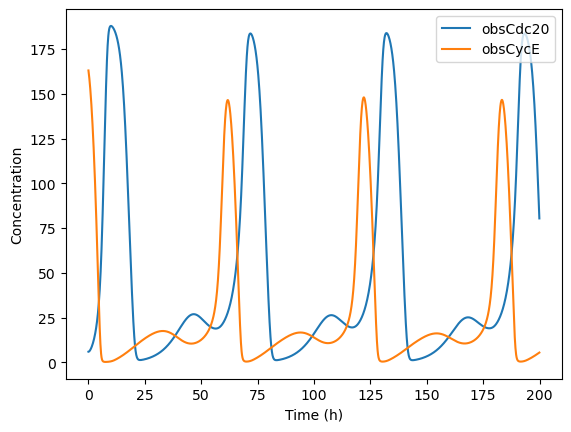

In [12]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

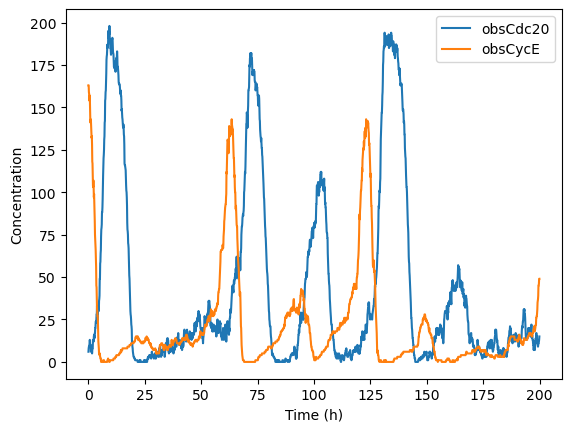

In [13]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


In [14]:
run_time = 120
observed_cells_time = 120

In [15]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 5
        
        fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_psoparam_{param_num}.csv')
        fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_psoparam_{param_num}.pkl')
        
        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)

            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            if SAVE_CELL_DATA:
                print(f"Saving to {fn_cells}...")
                with open(fn_cells, 'wb') as f:
                    pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_0_psoparam_2.csv...
elapsed time is 0:00:00.938833 minutes
4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_1_psoparam_2.csv...
elapsed time is 0:00:02.287665 minutes
4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_2_psoparam_2.csv...
elapsed time is 0:00:03.369690 minutes
4 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_0_psoparam_2.csv...
elapsed time is 0:00:06.734759 minutes
4 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_1_psoparam_2.csv...
elapsed time is 0:00:10.152720 minutes
4 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_2_psoparam_2.csv...
elapsed time is 0:00:13.684765 minutes
55 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_55 kPa erlotinib_0_psoparam_2.csv...
elapsed time is 0:00:15.085517 minutes
55 kPa erlotinib
Saving to C:\Users\olesk

In [16]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_psoparam_{param_num}.csv')
        fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_psoparam_{param_num}.pkl')

        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)
            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            if SAVE_CELL_DATA:
                print(f"Saving to {fn_cells}...")
                with open(fn_cells, 'wb') as f:
                    pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_0_psoparam_2.csv...
elapsed time is 0:00:30.717358 minutes
0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_1_psoparam_2.csv...
elapsed time is 0:00:31.812025 minutes
0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_2_psoparam_2.csv...
elapsed time is 0:00:32.710892 minutes
0.6 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_0_psoparam_2.csv...
elapsed time is 0:00:41.760243 minutes
0.6 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_1_psoparam_2.csv...
elapsed time is 0:00:50.386088 minutes
0.6 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_2_psoparam_2.csv...
elapsed time is 0:00:56.544910 minutes
